In [1]:
!unzip TRAINING.zip

Streaming output truncated to the last 5000 lines.
  inflating: TRAINING/Tomato_Late_blight/afb65a40-7512-4d2c-884e-56e6c5010511___RS_Late.B 5380.JPG  
  inflating: TRAINING/Tomato_Late_blight/aff90d5c-a3f2-445a-b125-717a00b21fb8___RS_Late.B 6624.JPG  
  inflating: TRAINING/Tomato_Late_blight/b07f5c6e-2e85-4b45-a166-522cc484619c___RS_Late.B 6276.JPG  
  inflating: TRAINING/Tomato_Late_blight/b09b2807-58ca-4708-904e-05de3032ef92___RS_Late.B 6345.JPG  
  inflating: TRAINING/Tomato_Late_blight/b0a1ada0-f496-46a3-827e-2d721dabee59___GHLB2 Leaf 9086.JPG  
  inflating: TRAINING/Tomato_Late_blight/b0e6fd13-ea0c-4e04-bdd3-70878b71f353___GHLB2 Leaf 106.1.JPG  
  inflating: TRAINING/Tomato_Late_blight/b0fbd7bd-f906-489b-96ff-a2683eb76dd3___RS_Late.B 6173.JPG  
  inflating: TRAINING/Tomato_Late_blight/b15c92e9-6973-415c-80fe-82703ff722f7___RS_Late.B 4994.JPG  
  inflating: TRAINING/Tomato_Late_blight/b17fad17-1d16-4a55-9b4e-d1a35ddbb611___GHLB2 Leaf 8933.JPG  
  inflating: TRAINING/Tomato_Late_bl

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing import image
print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
train_dir = "/content/TRAINING"
img_size = (224, 224)
batch_size = 32

datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

train_data = datagen.flow_from_directory(
    train_dir, target_size=img_size, batch_size=batch_size,
    class_mode='categorical', subset='training'
)
val_data = datagen.flow_from_directory(
    train_dir, target_size=img_size, batch_size=batch_size,
    class_mode='categorical', subset='validation'
)

Found 12813 images belonging to 10 classes.
Found 3198 images belonging to 10 classes.


In [4]:
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224,224,3))
base_model.trainable = False

model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(train_data.num_classes, activation='softmax')
])

model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

# Leenjii (Training) jalqaba
history = model.fit(train_data, validation_data=val_data, epochs=100)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/100
401/401 ━━━━━━━━━━━━━━━━━━━━ 75s 139ms/step - accuracy: 0.5811 - loss: 1.2837 - val_accuracy: 0.7745 - val_loss: 0.7288
Epoch 2/100
401/401 ━━━━━━━━━━━━━━━━━━━━ 30s 76ms/step - accuracy: 0.7750 - loss: 0.7119 - val_accuracy: 0.8302 - val_loss: 0.5374
Epoch 3/100
401/401 ━━━━━━━━━━━━━━━━━━━━ 27s 67ms/step - accuracy: 0.8193 - loss: 0.5634 - val_accuracy: 0.8624 - val_loss: 0.4525
Epoch 4/100
401/401 ━━━━━━━━━━━━━━━━━━━━ 25s 63ms/step - accuracy: 0.8431 - loss: 0.4839 - val_accuracy: 0.8684 - val_loss: 0.4102
Epoch 5/100
401/401 ━━━━━━━━━━━━━━━━━━━━ 25s 62ms/step - accuracy: 0.8620 - loss: 0.4302 - val_accuracy: 0.8806 - val_loss: 0.3772
Epoch 6/100
401/401 ━━━━━━━━━━━━━━━━━━━━ 25s 63ms/step - accuracy: 0.8752 - loss: 0.3873 - val_accuracy: 0.8890 - val_loss: 0.3493
Epoch 7/100
401/401 ━━━━━━━━━━━━━━━━━━━━ 26s 64ms/step - accuracy: 0.8861 - loss: 0.3536 - val_accuracy: 0.8931 - val_loss: 0.3313
Epoch 8/100
401/401 ━━━━━━━━━━━━━

In [5]:
model.save("tomato_disease_modelv3.h5")
print("our model is suucessfully saved")

our model is suucessfully saved


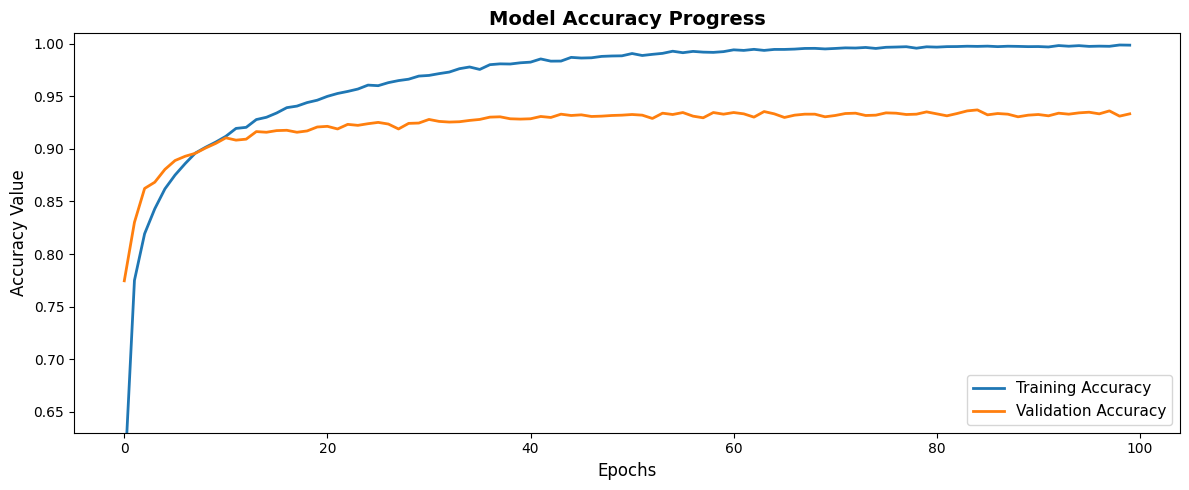

In [14]:
import numpy as np
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))
plt.plot(epochs_range, acc, label='Training Accuracy', linewidth=2)
plt.plot(epochs_range, val_acc, label='Validation Accuracy', linewidth=2)
plt.yticks(np.arange(0.65, 1.01, 0.05))
plt.ylim(0.63, 1.01) # Daangaa giraafichaa qulqulluuf

# Graph styling professional gochuuf
plt.title('Model Accuracy Progress', fontsize=14, weight='bold')
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy Value', fontsize=12)
plt.legend(loc='lower right', fontsize=11)
plt.grid(False)
plt.tight_layout()

plt.show()

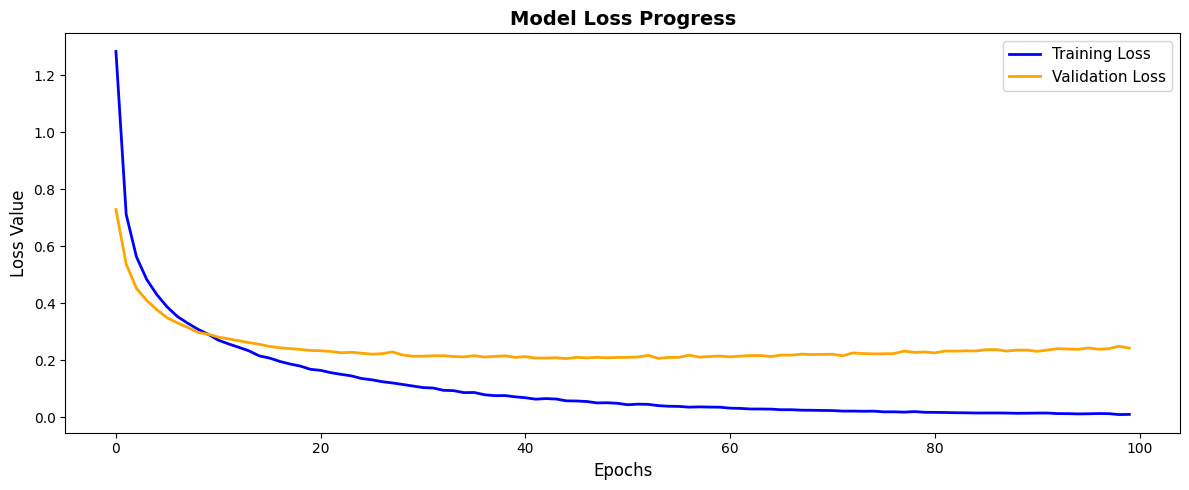

In [15]:
import matplotlib.pyplot as plt

# Extract loss data from training history
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(len(loss))

# Plotting Training and Validation Loss
plt.figure(figsize=(12, 5))
plt.plot(epochs_range, loss, label='Training Loss', color='blue', linewidth=2)
plt.plot(epochs_range, val_loss, label='Validation Loss', color='orange', linewidth=2)

# Graph styling
plt.title('Model Loss Progress', fontsize=14, weight='bold')
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss Value', fontsize=12)
plt.legend(loc='upper right', fontsize=11)
plt.grid(False)
plt.tight_layout()
plt.show()

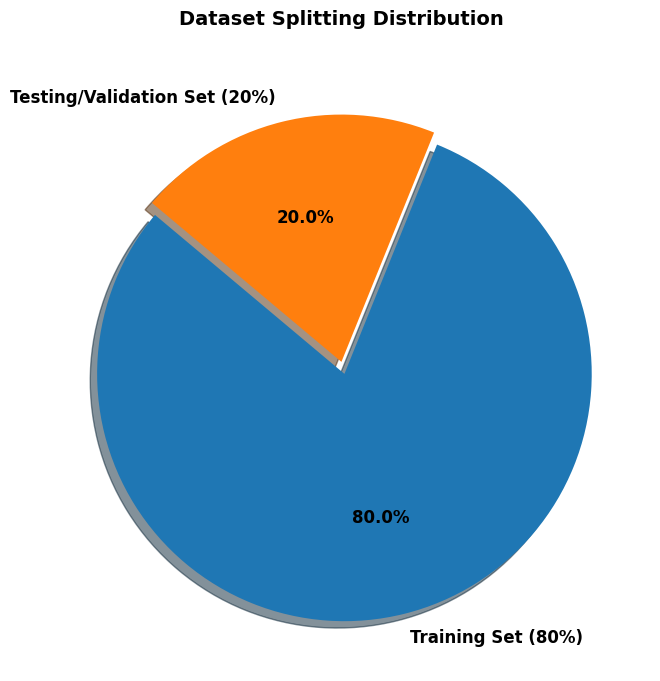

In [16]:
import matplotlib.pyplot as plt

# Data distribution setup (80% Training, 20% Testing/Validation)
labels = ['Training Set (80%)', 'Testing/Validation Set (20%)']
sizes = [80, 20]
colors = ['#1f77b4', '#ff7f0e'] # Matching Blue and Orange theme
explode = (0.05, 0)  # Slightly separate the Training slice for emphasis

# Plotting the pie chart
plt.figure(figsize=(7, 7))
plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%',
        shadow=True, startangle=140, textprops={'fontsize': 12, 'weight': 'bold'})

# Graph styling
plt.title('Dataset Splitting Distribution', fontsize=14, weight='bold', pad=20)
plt.tight_layout()
plt.show()

In [18]:
# STEP 1: Install the necessary library (Run this first)
!pip install gradio -q

import gradio as gr
import numpy as np
import cv2
import tensorflow as tf
from tensorflow.keras.models import load_model

# STEP 2: Load the "AI Brain" (Model)
# Ensure 'tomato_disease_modelv3.h5' is uploaded to your files
try:
    model = load_model('tomato_disease_modelv3.h5')
    print("Model loaded successfully!")
except Exception as e:
    print(f"Error: Could not find the model file. Please upload it. \n{e}")

# STEP 3: Define the Disease Names
class_names = [
    'Bacterial_Spot', 'Early_Blight', 'Late_Blight', 'Leaf_Mold',
    'Septoria_Leaf_Spot', 'Spider_Mites', 'Target_Spot',
    'Yellow_Leaf_Curl_Virus', 'Mosaic_Virus', 'Healthy'
]

# STEP 4: The Prediction Function
def predict_tomato_disease(input_img):
    if input_img is None:
        return "Please upload an image."

    # Preprocess the image (Resize to 224x224 and Normalize)
    img_resized = cv2.resize(input_img, (224, 224))
    img_array = img_resized / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # Make the prediction
    prediction = model.predict(img_array)
    index = np.argmax(prediction)
    confidence = np.max(prediction) * 100

    result = class_names[index]

    # Display the final output
    return f"DISEASE: {result} \nCONFIDENCE: {confidence:.2f}%"

# STEP 5: Create the Upload Interface (Web App)
app = gr.Interface(
    fn=predict_tomato_disease,
    inputs=gr.Image(label="Upload Leaf Photo"),
    outputs=gr.Textbox(label="AI Result"),
    title=" Tomato Disease Recognition System",
    description="Professional AI project. Simply drag and drop a tomato leaf image to detect the disease."
)

# STEP 6: Launch the App
app.launch(share=True)

Model loaded successfully!
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://1493fca43d1d91c146.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
